CSV files available in Colab:
['/content/salary.csv']

First 5 rows:
   age          workclass  fnlwgt   education  education-num  \
0   39          State-gov   77516   Bachelors             13   
1   50   Self-emp-not-inc   83311   Bachelors             13   
2   38            Private  215646     HS-grad              9   
3   53            Private  234721        11th              7   
4   28            Private  338409   Bachelors             13   

        marital-status          occupation    relationship    race      sex  \
0        Never-married        Adm-clerical   Not-in-family   White     Male   
1   Married-civ-spouse     Exec-managerial         Husband   White     Male   
2             Divorced   Handlers-cleaners   Not-in-family   White     Male   
3   Married-civ-spouse   Handlers-cleaners         Husband   Black     Male   
4   Married-civ-spouse      Prof-specialty            Wife   Black   Female   

   capital-gain  capital-loss  hours-per-week  native-country  salary  

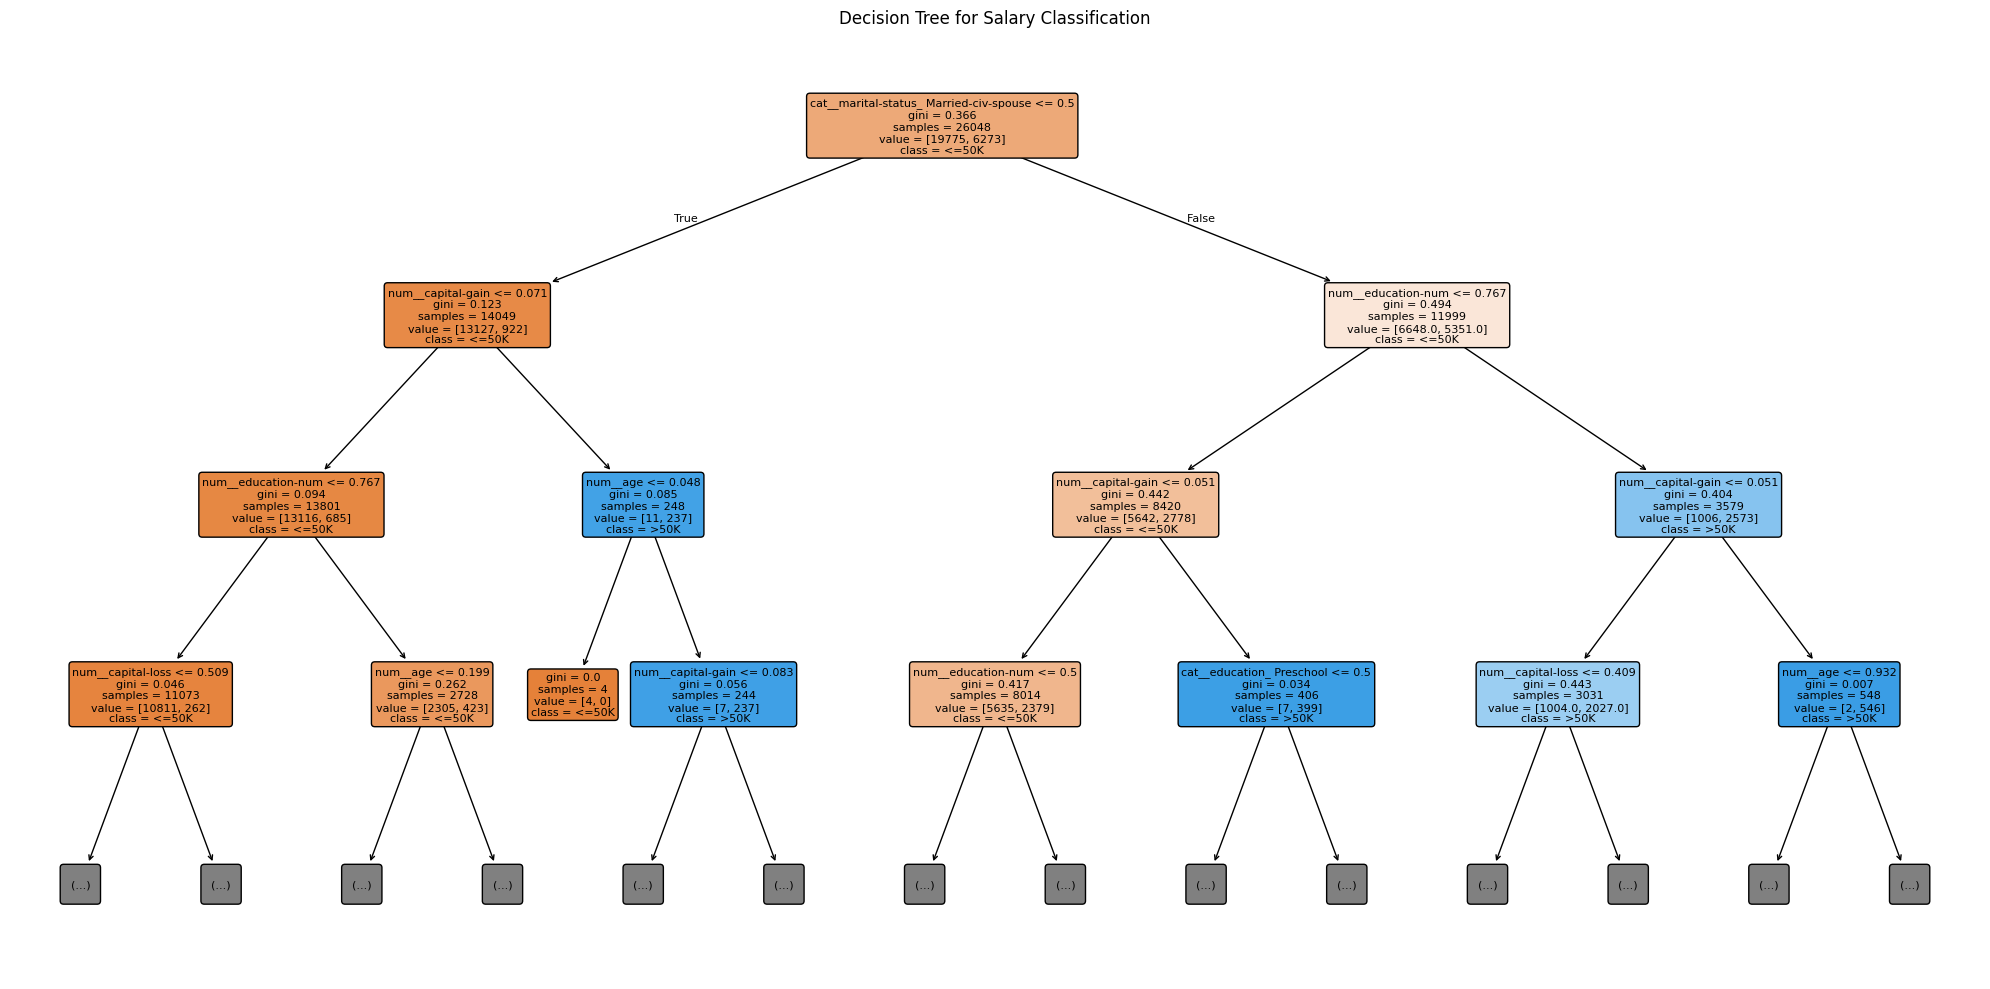


========== PRUNED DECISION TREE ==========
Accuracy: 82.91 %
Tree depth: 2
Number of leaves: 4

========== K-NN CLASSIFICATION ==========
Accuracy: 82.77 %

========== NAIVE BAYES CLASSIFICATION ==========
Accuracy: 80.02 %

========== MODEL COMPARISON ==========
        Model  Accuracy (%)
Decision Tree         84.66
  Pruned Tree         82.91
         K-NN         82.77
  Naive Bayes         80.02


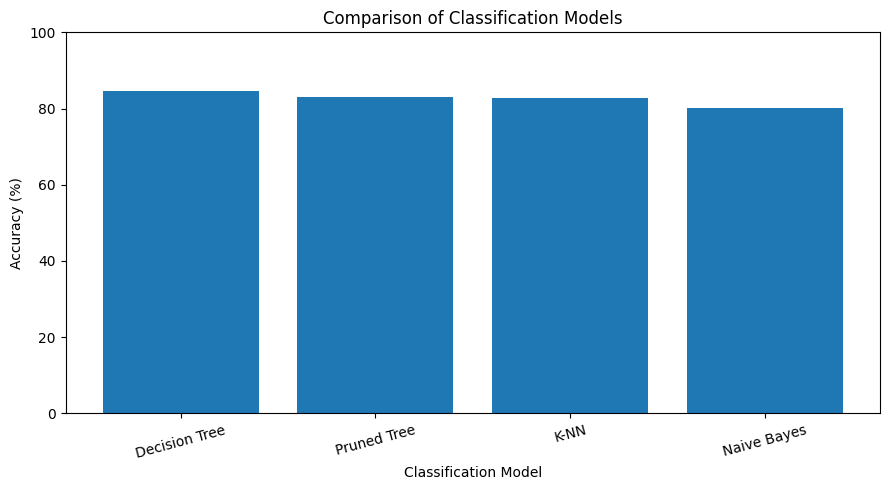


========== RESULT ==========
Decision Tree classification completed.
Pruning and model comparison were performed.
The best model on this test split is: Decision Tree


In [1]:

# MACHINE LEARNING LAB - CO2
# PROGRAM 8: DECISION TREE CLASSIFICATION
# Dataset: Kaggle Salary Dataset
# Platform: Google Colab

import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

# --------------------------------------------------
# 1. LOAD THE KAGGLE DATASET
# --------------------------------------------------

print("CSV files available in Colab:")
csv_files = glob.glob("/content/*.csv")
print(csv_files)

# Change this path if your downloaded CSV has another name.
CSV_PATH = "/content/salary.csv"

if not os.path.exists(CSV_PATH):
    if len(csv_files) == 1:
        CSV_PATH = csv_files[0]
    else:
        raise FileNotFoundError(
            "Set CSV_PATH to the exact name of your uploaded salary CSV."
        )

df = pd.read_csv(CSV_PATH)

# Clean column names
df.columns = df.columns.str.strip()

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())


# --------------------------------------------------
# 2. PREPARE THE TARGET VARIABLE
# --------------------------------------------------

# Find a salary-related column
salary_columns = [
    col for col in df.columns
    if "salary" in col.lower() or "income" in col.lower()
]

if not salary_columns:
    raise ValueError(
        "No salary/income column found. Check the printed column names "
        "and select the correct target column."
    )

target_col = salary_columns[0]
print("\nSelected target column:", target_col)

# Convert salary values to numeric when possible.
# Handles values such as "$85,000" or "85000".
salary_numeric = pd.to_numeric(
    df[target_col].astype(str)
      .str.replace(r"[$,]", "", regex=True)
      .str.strip(),
    errors="coerce"
)

if salary_numeric.notna().mean() >= 0.8:
    # Numeric salary: create Low/High classes using the median.
    median_salary = salary_numeric.median()
    valid_rows = salary_numeric.notna()

    df = df.loc[valid_rows].copy()
    salary_numeric = salary_numeric.loc[valid_rows]

    df["SalaryCategory"] = np.where(
        salary_numeric >= median_salary, "High", "Low"
    )
    target_col = "SalaryCategory"

    print("Median salary used as threshold:", median_salary)
    print("Target classes created: Low and High")

else:
    # If salary already contains categories, use them directly.
    df = df.dropna(subset=[target_col]).copy()

    # Avoid accidentally treating every unique salary amount as a class.
    if df[target_col].nunique() > 20:
        raise ValueError(
            "The salary column is not clearly numeric or categorical. "
            "Inspect df.head() and choose the correct classification target."
        )

    df[target_col] = df[target_col].astype(str).str.strip()

print("\nTarget class distribution:")
print(df[target_col].value_counts())

if df[target_col].nunique() < 2:
    raise ValueError("The target must contain at least two classes.")


# --------------------------------------------------
# 3. SELECT FEATURES AND TARGET
# --------------------------------------------------

# Remove target and columns that are likely identifiers.
X = df.drop(columns=[target_col]).copy()
y = df[target_col].copy()

# Remove original numeric salary if SalaryCategory is the target.
# This prevents the original salary value from revealing the answer.
for col in list(X.columns):
    if "salary" in col.lower() or "income" in col.lower():
        X = X.drop(columns=[col])

# Remove common identifier columns.
id_cols = [
    col for col in X.columns
    if col.lower() in ["id", "index", "employee_id", "employeeid"]
]
X = X.drop(columns=id_cols, errors="ignore")

# Remove completely empty columns.
X = X.dropna(axis=1, how="all")

# Treat remaining columns as numeric or categorical.
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

if len(numeric_cols) + len(categorical_cols) == 0:
    raise ValueError("No usable feature columns were found.")

print("\nNumeric features:", numeric_cols)
print("Categorical features:", categorical_cols)


# --------------------------------------------------
# 4. SPLIT THE DATA
# --------------------------------------------------

# Stratify when each class has enough examples.
class_counts = y.value_counts()
stratify_y = y if class_counts.min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=stratify_y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# --------------------------------------------------
# 5. PREPROCESS THE DATA
# --------------------------------------------------

# Numeric: fill missing values and scale to non-negative values.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

# Categorical: fill missing values and convert text to numbers.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])


# --------------------------------------------------
# 6. TRAIN THE DECISION TREE
# --------------------------------------------------

decision_tree = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        random_state=42
    ))
])

decision_tree.fit(X_train, y_train)
tree_pred = decision_tree.predict(X_test)

tree_accuracy = accuracy_score(y_test, tree_pred)

print("\n========== DECISION TREE ==========")
print("Accuracy:", round(tree_accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, tree_pred, zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_test, tree_pred))


# --------------------------------------------------
# 7. VISUALIZE THE DECISION TREE
# --------------------------------------------------

trained_tree = decision_tree.named_steps["classifier"]
feature_names = decision_tree.named_steps[
    "preprocessor"
].get_feature_names_out()

plt.figure(figsize=(20, 10))
plot_tree(
    trained_tree,
    feature_names=feature_names,
    class_names=[str(c) for c in trained_tree.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree for Salary Classification")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 8. PRUNING THE DECISION TREE
# --------------------------------------------------

# A smaller maximum depth restricts tree complexity.
pruned_tree = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=2,
        min_samples_leaf=5,
        random_state=42
    ))
])

pruned_tree.fit(X_train, y_train)
pruned_pred = pruned_tree.predict(X_test)

pruned_accuracy = accuracy_score(y_test, pruned_pred)

print("\n========== PRUNED DECISION TREE ==========")
print("Accuracy:", round(pruned_accuracy * 100, 2), "%")
print("Tree depth:", pruned_tree.named_steps["classifier"].get_depth())
print("Number of leaves:",
      pruned_tree.named_steps["classifier"].get_n_leaves())


# --------------------------------------------------
# 9. COMPARE WITH K-NN
# --------------------------------------------------

knn_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)
knn_accuracy = accuracy_score(y_test, knn_pred)

print("\n========== K-NN CLASSIFICATION ==========")
print("Accuracy:", round(knn_accuracy * 100, 2), "%")


# --------------------------------------------------
# 10. COMPARE WITH NAIVE BAYES
# --------------------------------------------------

nb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", MultinomialNB())
])

nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)
nb_accuracy = accuracy_score(y_test, nb_pred)

print("\n========== NAIVE BAYES CLASSIFICATION ==========")
print("Accuracy:", round(nb_accuracy * 100, 2), "%")


# --------------------------------------------------
# 11. COMPARE ALL MODELS
# --------------------------------------------------

model_names = [
    "Decision Tree",
    "Pruned Tree",
    "K-NN",
    "Naive Bayes"
]

accuracies = [
    tree_accuracy,
    pruned_accuracy,
    knn_accuracy,
    nb_accuracy
]

comparison = pd.DataFrame({
    "Model": model_names,
    "Accuracy (%)": [round(a * 100, 2) for a in accuracies]
})

print("\n========== MODEL COMPARISON ==========")
print(comparison.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.bar(model_names, [a * 100 for a in accuracies])
plt.xlabel("Classification Model")
plt.ylabel("Accuracy (%)")
plt.title("Comparison of Classification Models")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 12. RESULT
# --------------------------------------------------

print("\n========== RESULT ==========")
print("Decision Tree classification completed.")
print("Pruning and model comparison were performed.")
print("The best model on this test split is:",
      model_names[int(np.argmax(accuracies))])
